# Import

In [36]:
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display

# Đọc data

In [37]:
# Đọc lại đúng các file đã lưu từ notebook 01, không dùng biến cũ trong kernel.
X_train_model = pd.read_pickle("04_output/02_clean_data/X_train_model.pkl")
X_test_model = pd.read_pickle("04_output/02_clean_data/X_test_model.pkl")
y_train = pd.read_pickle("04_output/02_clean_data/y_train.pkl")
y_test = pd.read_pickle("04_output/02_clean_data/y_test.pkl")
arm_train = pd.read_pickle("04_output/02_clean_data/arm_train.pkl")
arm_test = pd.read_pickle("04_output/02_clean_data/arm_test.pkl")

OUT_DIR = Path("04_output/03_association_classification")
OUT_DIR.mkdir(parents=True, exist_ok=True)

selected_features = X_train_model.columns.tolist()
RANDOM_STATE = 42

print("Train/Test:", X_train_model.shape, X_test_model.shape)
print("Tỷ lệ attack:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))

Train/Test: (1464101, 39) (371127, 39)
Tỷ lệ attack: 0.2415 / 0.2371


# Khai phá luật kết hợp

In [38]:
# MINING_SIZE = len(y_train)//2
MINING_SIZE = 300000
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.55

# Khai phá luật trên toàn bộ features đã chọn
arm_cols = selected_features.copy()
missing_train = set(arm_cols) - set(arm_train.columns)
missing_test = set(arm_cols) - set(arm_test.columns)
if missing_train or missing_test:
    raise ValueError(
        f"Bảng item không khớp feature đã chọn: train thiếu {sorted(missing_train)}, "
        f"test thiếu {sorted(missing_test)}"
    )
if len(arm_cols) < 5:
    raise ValueError("Cần ít nhất 5 thuộc tính rời rạc hóa để khai phá luật.")

if len(y_train) > MINING_SIZE:
    mining_idx, _ = train_test_split(
        y_train.index, train_size=MINING_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    mining_idx = y_train.index

basket = arm_train.loc[mining_idx, arm_cols]
transactions = [
    frozenset([*row, f"class={int(label)}"])
    for row, label in zip(basket.astype(str).itertuples(index=False, name=None),
                          y_train.loc[mining_idx])
]
MIN_COUNT = int(np.ceil(MIN_SUPPORT * len(transactions)))

print("Thuộc tính giao dịch:", arm_cols)
print("Số giao dịch:", len(transactions), "| Ngưỡng support:", MIN_COUNT)

Thuộc tính giao dịch: ['bwd_pkt_len_mean', 'bwd_subflow_bytes_mean', 'pkt_len_max', 'fwd_pkt_hdr_len_tot', 'flag_ack', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_subflow_bytes_mean', 'fwd_pkt_len_tot', 'bwd_pkt_hdr_len_tot', 'bwd_tcp_init_win_bytes', 'iat_max', 'fwd_iat_max', 'fwd_tcp_init_win_bytes', 'bwd_pkt_len_std', 'flag_SYN', 'bytes_per_s', 'bwd_pkt_per_s', 'fwd_pkt_len_std', 'bwd_iat_max', 'fwd_subflow_pkt_mean', 'fwd_pkt_cnt', 'down_up_ratio', 'fwd_iat_std', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_subflow_pkt_mean', 'bwd_non_empty_pkt_cnt', 'iat_std', 'bwd_pkt_hdr_len_min', 'pkt_len_min', 'ip_prot', 'iat_min', 'flag_psh', 'bwd_iat_min', 'fwd_iat_min', 'bwd_iat_std', 'bwd_bulk_bytes_mean', 'flag_rst']
Số giao dịch: 300000 | Ngưỡng support: 6000


## Giao dịch chứa tập mục

In [39]:
def make_vertical(rows):
    vertical = defaultdict(set)
    for tid, row in enumerate(rows):
        for item in row:
            vertical[item].add(tid)
    return dict(vertical)


def matching_tids(items, vertical):
    sets = [vertical[item] for item in items]
    if not sets:
        return set()
    result = sets[0].copy()
    for tids in sets[1:]:
        result.intersection_update(tids)
    return result


def apriori_target(vertical, min_count, target_item="class=1"):
    """Apriori cho các tập tối đa 3 mục có chứa nhãn attack."""
    target_tids = vertical[target_item]
    frequent = {frozenset((target_item,)): len(target_tids)}
    level = []
    for item, tids in vertical.items():
        if item.startswith("class="):
            continue
        count = len(tids & target_tids)
        if count >= min_count:
            frequent[frozenset((item, target_item))] = count
            level.append(item)

    # Chỉ ghép các mục đã phổ biến ở mức trước (tính chất Apriori).
    for left, right in combinations(sorted(level), 2):
        count = len(vertical[left] & vertical[right] & target_tids)
        if count >= min_count:
            frequent[frozenset((left, right, target_item))] = count
    return frequent


vertical = make_vertical(transactions)
sets_apriori = apriori_target(vertical, MIN_COUNT)
print("Số item khác nhau:", len(vertical))
print("Số tập mục Apriori chứa class=1:", len(sets_apriori))


Số item khác nhau: 149
Số tập mục Apriori chứa class=1: 2184


## FP-Growth

In [40]:
import warnings

from mlxtend.frequent_patterns import fpgrowth as mlxtend_fpgrowth
from mlxtend.preprocessing import TransactionEncoder


def fp_growth_target(rows, min_count, target_item="class=1", max_len=3):
    """Trả về {frozenset(items): support_count} cho các tập chứa target_item."""
    if min_count < 1 or max_len < 1:
        raise ValueError("min_count và max_len phải là số nguyên dương")

    target_rows = [
        [item for item in row if item != target_item]
        for row in rows if target_item in row
    ]
    target_count = len(target_rows)
    if target_count < min_count:
        return {}

    result = {frozenset((target_item,)): target_count}
    if max_len == 1 or not any(target_rows):
        return result

    encoder = TransactionEncoder()
    matrix = encoder.fit(target_rows).transform(target_rows, sparse=True)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", message="Allowing arbitrary scalar fill_value", category=FutureWarning
        )
        one_hot = pd.DataFrame.sparse.from_spmatrix(matrix, columns=encoder.columns_)

    patterns = mlxtend_fpgrowth(
        one_hot,
        min_support=min_count / target_count,
        use_colnames=True,
        max_len=max_len - 1,
    )
    result.update({
        itemset | {target_item}: int(round(support * target_count))
        for support, itemset in patterns.itertuples(index=False, name=None)
    })
    return result


sets_fp = fp_growth_target(transactions, MIN_COUNT, target_item="class=1", max_len=3)
print("Số tập mục FP-Growth chứa class=1:", len(sets_fp))
if sets_apriori != sets_fp:
    raise AssertionError("Apriori và FP-Growth phải có cùng tập mục và support.")

Số tập mục FP-Growth chứa class=1: 2184


## CHARM (tập mục đóng)

In [41]:
def charm_closed(vertical, min_count, max_prefix_len=3):
    nodes = [
        (frozenset([item]), tids.copy())
        for item, tids in vertical.items()
        if len(tids) >= min_count
    ]
    closed = {}

    def extend(nodes):
        nodes.sort(key=lambda pair: (len(pair[1]), tuple(sorted(pair[0]))))
        i = 0
        while i < len(nodes):
            xi, ti = nodes[i]
            children = []
            j = i + 1
            while j < len(nodes):
                xj, tj = nodes[j]
                both = ti & tj
                if len(both) < min_count:
                    j += 1
                    continue

                merged = xi | xj
                if ti == tj:
                    # Hai tập xuất hiện trên đúng cùng giao dịch.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    nodes.pop(j)
                elif ti < tj:
                    # Mọi giao dịch có xi cũng có xj.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    j += 1
                elif ti > tj:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    nodes.pop(j)
                else:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    j += 1

            closure = frozenset(xi | {
                item for item, tids in vertical.items() if ti <= tids
            })
            closed[closure] = len(ti)
            if children:
                extend(children)
            i += 1

    extend(nodes)
    return closed


# Chỉ khai phá tập đóng có thể dẫn tới class=1. TID đã được giới hạn
# theo nhãn attack; support vẫn tính trên toàn bộ tập giao dịch.
attack_tids = vertical["class=1"]
target_vertical = {
    item: tids & attack_tids
    for item, tids in vertical.items()
    if not item.startswith("class=") and len(tids & attack_tids) >= MIN_COUNT
}
sets_charm = {
    closed | {"class=1"}: count
    for closed, count in charm_closed(target_vertical, MIN_COUNT, max_prefix_len=2).items()
}
print("Số tập mục đóng CHARM chứa class=1:", len(sets_charm))

Số tập mục đóng CHARM chứa class=1: 1113


## Chọn 3 luật mỗi phương pháp

In [42]:
def candidate_rules(itemsets, vertical, n):
    base_attack = len(vertical["class=1"]) / n
    rows = []
    for pattern, count in itemsets.items():
        if "class=1" not in pattern or "class=0" in pattern:
            continue
        antecedent = pattern - {"class=1"}
        if not 1 <= len(antecedent) <= 2:
            continue
        tids = matching_tids(antecedent, vertical)
        confidence = count / len(tids)
        lift = confidence / base_attack
        if confidence >= MIN_CONFIDENCE and lift > 1:
            rows.append({
                "antecedent": antecedent, "tids": tids,
                "support": count / n, "coverage": len(tids) / n,
                "confidence": confidence, "lift": lift,
            })
    return rows


def select_three(candidates):
    selected = []
    covered = set()
    remaining = candidates.copy()
    while remaining and len(selected) < 3:
        best = max(remaining, key=lambda row: (
            len(row["tids"] - covered),
            row["confidence"], row["lift"], tuple(sorted(row["antecedent"])),
        ))
        selected.append(best)
        covered.update(best["tids"])
        remaining.remove(best)
    if len(selected) < 3:
        raise ValueError("Chưa có đủ 3 luật attack. Giảm MIN_SUPPORT hoặc MIN_CONFIDENCE rồi chạy lại trên train.")
    return selected

def expand_charm_target(closed_sets, vertical, target_item="class=1"):
    """Suy ra tập phổ biến ngắn từ tập đóng CHARM, tính support chính xác."""
    antecedents = set()
    for closed in closed_sets:
        if target_item not in closed or "class=0" in closed:
            continue
        items = sorted(closed - {target_item})
        for size in (1, 2):
            antecedents.update(combinations(items, size))

    target_tids = vertical[target_item]
    return {
        frozenset((*items, target_item)): len(target_tids.intersection(*(vertical[item] for item in items)))
        for items in antecedents
    }


sets_charm_rules = expand_charm_target(sets_charm, vertical)
print("Số tập mục CHARM suy ra để tạo luật:", len(sets_charm_rules))
rules_apriori = select_three(candidate_rules(sets_apriori, vertical, len(transactions)))
rules_fp = select_three(candidate_rules(sets_fp, vertical, len(transactions)))
rules_charm = select_three(candidate_rules(sets_charm_rules, vertical, len(transactions)))


def rule_flags(items, rules):
    flags = pd.DataFrame(index=items.index)
    for i, rule in enumerate(rules, 1):
        match = pd.Series(True, index=items.index)
        for item in rule["antecedent"]:
            col = item.split("=", 1)[0]
            match &= items[col].astype(str).eq(item)
        flags[f"Rule_{i}"] = match.astype("int8")
    return flags


def describe_rules(rules, method, items, labels):
    flags = rule_flags(items, rules)
    base_attack = labels.mean()
    rows = []
    for i, rule in enumerate(rules, 1):
        mask = flags[f"Rule_{i}"].astype(bool)
        coverage = mask.mean()
        support = (mask & labels.eq(1)).mean()
        confidence = support / coverage if coverage else 0
        rows.append({
            "Phương pháp": method, "Luật": f"Rule_{i}",
            "Tiền đề": " & ".join(sorted(rule["antecedent"])),
            "Kết luận": "attack", "Coverage": coverage,
            "Support": support, "Confidence": confidence,
            "Lift": confidence / base_attack,
        })
    return pd.DataFrame(rows), flags


table_apriori, flags_train_apriori = describe_rules(rules_apriori, "Apriori", arm_train, y_train)
table_fp, flags_train_fp = describe_rules(rules_fp, "FP-Growth", arm_train, y_train)
table_charm, flags_train_charm = describe_rules(rules_charm, "CHARM", arm_train, y_train)
rules_table = pd.concat([table_apriori, table_fp, table_charm], ignore_index=True)
display(rules_table.round(4))
rules_table.to_csv("04_output/03_association_classification/association_rules.csv", index=False)

Số tập mục CHARM suy ra để tạo luật: 2089


,Phương pháp,Luật,Tiền đề,Kết luận,Coverage,Support,Confidence,Lift
0,Apriori,Rule_1,"iat_min=(4.5, 164.5]",attack,0.3029,0.1711,0.5649,2.3389
1,Apriori,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",attack,0.2397,0.1416,0.5908,2.4463
2,Apriori,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146]",attack,0.2866,0.1829,0.6379,2.6413
3,FP-Growth,Rule_1,"iat_min=(4.5, 164.5]",attack,0.3029,0.1711,0.5649,2.3389
4,FP-Growth,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",attack,0.2397,0.1416,0.5908,2.4463
5,FP-Growth,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146]",attack,0.2866,0.1829,0.6379,2.6413
6,CHARM,Rule_1,"iat_min=(4.5, 164.5]",attack,0.3029,0.1711,0.5649,2.3389
7,CHARM,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",attack,0.2397,0.1416,0.5908,2.4463
8,CHARM,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146]",attack,0.2866,0.1829,0.6379,2.6413


## Truy vết từng lượt chọn luật

Chọn luật phủ thêm nhiều giao dịch train nhất. Confidence và lift chỉ dùng để phá hòa; bảng ghi độ phủ tăng thêm và độ phủ chung sau mỗi lượt.


In [43]:
trace_rows = []
for method, rules in [
    ("Apriori", rules_apriori),
    ("FP-Growth", rules_fp),
    ("CHARM", rules_charm),
]:
    covered = set()
    for turn, rule in enumerate(rules, 1):
        new_tids = rule["tids"] - covered
        covered.update(rule["tids"])
        consequent = rule.get("consequent", "attack").removeprefix("class=")
        trace_rows.append({
            "Phương pháp": method,
            "Lượt": turn,
            "Luật chọn": " & ".join(sorted(rule["antecedent"])) + " ⇒ " + consequent,
            "Phủ thêm (%)": 100 * len(new_tids) / len(transactions),
            "Phủ chung sau lượt (%)": 100 * len(covered) / len(transactions),
            "Confidence": rule["confidence"],
            "Lift": rule["lift"],
        })

selection_trace = pd.DataFrame(trace_rows)
display(selection_trace.round(3))
selection_trace.to_csv("04_output/03_association_classification/rule_selection_trace.csv", index=False)


,Phương pháp,Lượt,Luật chọn,Phủ thêm (%),Phủ chung sau lượt (%),Confidence,Lift
0,Apriori,1,"iat_min=(4.5, 164.5] ⇒ attack",30.209,30.209,0.566,2.344
1,Apriori,2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",13.785,43.994,0.591,2.445
2,Apriori,3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",5.547,49.541,0.637,2.637
3,FP-Growth,1,"iat_min=(4.5, 164.5] ⇒ attack",30.209,30.209,0.566,2.344
4,FP-Growth,2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",13.785,43.994,0.591,2.445
5,FP-Growth,3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",5.547,49.541,0.637,2.637
6,CHARM,1,"iat_min=(4.5, 164.5] ⇒ attack",30.209,30.209,0.566,2.344
7,CHARM,2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...",13.785,43.994,0.591,2.445
8,CHARM,3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",5.547,49.541,0.637,2.637


## Bảng nội dung luật và đối chiếu ba phương pháp

Mỗi dòng viết rõ điều kiện và kết luận. Bảng đối chiếu đếm luật trùng theo cả tiền đề và kết luận; “cùng bộ” không phụ thuộc thứ tự Rule_1/2/3.

`Q1`–`Q4` là các nhóm tứ phân vị tạo từ train. `Rule_i=1` khi tiền đề đúng; không dùng kết luận thật để tạo cột này.


In [44]:
rule_expressions = rules_table[["Phương pháp", "Luật", "Tiền đề", "Kết luận"]].copy()
rule_expressions["Luật kết hợp"] = (
    rule_expressions["Tiền đề"] + " ⇒ " + rule_expressions["Kết luận"]
)
rule_expressions = rule_expressions[["Phương pháp", "Luật", "Luật kết hợp"]]
display(rule_expressions)
rule_expressions.to_csv("04_output/03_association_classification/rule_expressions.csv", index=False)


,Phương pháp,Luật,Luật kết hợp
0,Apriori,Rule_1,"iat_min=(4.5, 164.5] ⇒ attack"
1,Apriori,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &..."
2,Apriori,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack"
3,FP-Growth,Rule_1,"iat_min=(4.5, 164.5] ⇒ attack"
4,FP-Growth,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &..."
5,FP-Growth,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack"
6,CHARM,Rule_1,"iat_min=(4.5, 164.5] ⇒ attack"
7,CHARM,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &..."
8,CHARM,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack"


In [45]:
method_order = ["Apriori", "FP-Growth", "CHARM"]
method_rules = {}
for method in method_order:
    rows = rules_table.loc[
        rules_table["Phương pháp"] == method, ["Tiền đề", "Kết luận"]
    ]
    method_rules[method] = list(rows.itertuples(index=False, name=None))

comparison_rows = []
for left, right in combinations(method_order, 2):
    left_rules = method_rules[left]
    right_rules = method_rules[right]
    common = len(set(left_rules) & set(right_rules))
    comparison_rows.append({
        "So sánh": f"{left} / {right}",
        "Số luật trùng": f"{common}/3",
        "Cùng bộ 3 luật": "Có" if set(left_rules) == set(right_rules) else "Không",
        "Cùng thứ tự": "Có" if left_rules == right_rules else "Không",
    })

rule_comparison = pd.DataFrame(comparison_rows)
display(rule_comparison)
rule_comparison.to_csv("04_output/03_association_classification/rule_comparison.csv", index=False)


,So sánh,Số luật trùng,Cùng bộ 3 luật,Cùng thứ tự
0,Apriori / FP-Growth,3/3,Có,Có
1,Apriori / CHARM,3/3,Có,Có
2,FP-Growth / CHARM,3/3,Có,Có


## So sánh coverage của ba phương pháp

In [46]:
coverage_table = pd.DataFrame([
    {
        "Phương pháp": method,
        "Luật 1 (%)": 100 * flags["Rule_1"].mean(),
        "Luật 2 (%)": 100 * flags["Rule_2"].mean(),
        "Luật 3 (%)": 100 * flags["Rule_3"].mean(),
        "Độ phủ chung (%)": 100 * flags.any(axis=1).mean(),
    }
    for method, flags in [
        ("Apriori", flags_train_apriori),
        ("FP-Growth", flags_train_fp),
        ("CHARM", flags_train_charm),
    ]
])
display(coverage_table.round(2))
coverage_table.to_csv("04_output/03_association_classification/rule_coverage.csv", index=False)

# Apriori và FP-Growth tìm cùng các tập phổ biến; CHARM khôi phục
# tập ngắn từ tập đóng. Các phương pháp có thể chọn cùng bộ ba luật.

,Phương pháp,Luật 1 (%),Luật 2 (%),Luật 3 (%),Độ phủ chung (%)
0,Apriori,30.29,23.97,28.66,49.57
1,FP-Growth,30.29,23.97,28.66,49.57
2,CHARM,30.29,23.97,28.66,49.57


# Phân lớp với luật của cả ba phương pháp

Dùng đúng ba luật đã chọn riêng cho Apriori, CHARM và FP-Growth ở trên. Bốn kịch bản dùng cùng tập train/test và cùng các feature gốc: `Classification basic` không có cột luật; mỗi kịch bản còn lại thêm `Rule_1`–`Rule_3` từ phương pháp tương ứng. Mỗi kịch bản chạy Logistic Regression, Decision Tree và Random Forest.


In [47]:
baseline_label = "Classification basic"
classification_rules = {
    "Classification + Apriori": rules_apriori,
    "Classification + CHARM": rules_charm,
    "Classification + FP-Growth": rules_fp,
}
dataset_methods = {
    "Classification + Apriori": "Apriori",
    "Classification + CHARM": "CHARM",
    "Classification + FP-Growth": "FP-Growth",
}
flags_train_by_dataset = {
    "Classification + Apriori": flags_train_apriori,
    "Classification + CHARM": flags_train_charm,
    "Classification + FP-Growth": flags_train_fp,
}

# Coverage của đúng bộ ba luật đưa vào từng kịch bản phân lớp.
classification_coverage = pd.DataFrame([
    {
        "Kịch bản phân lớp": dataset,
        "Phương pháp khai phá luật": dataset_methods[dataset],
        "Số dòng train được phủ": int(flags.any(axis=1).sum()),
        "Độ phủ chung train (%)": 100 * flags.any(axis=1).mean(),
    }
    for dataset, flags in flags_train_by_dataset.items()
])
display(classification_coverage.round(3))
classification_coverage.to_csv(
    "04_output/03_association_classification/classification_rule_coverage.csv",
    index=False,
)


def rule_source_features(rules):
    sources = {
        item.split("=", 1)[0]
        for rule in rules
        for item in rule["antecedent"]
    }
    return [col for col in selected_features if col in sources]


# Cùng mẫu train/test cho cả bốn kịch bản, giữ feature gốc khi thêm luật.
MODEL_TRAIN_SIZE = 120_000
if len(y_train) > MODEL_TRAIN_SIZE:
    model_idx, _ = train_test_split(
        y_train.index, train_size=MODEL_TRAIN_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    model_idx = y_train.index

X_train_basic = X_train_model.loc[model_idx].copy()
X_test_basic = X_test_model.copy()
y_train_fit = y_train.loc[model_idx]
datasets = {baseline_label: (X_train_basic, X_test_basic)}
for dataset, rules in classification_rules.items():
    X_fit = X_train_basic.join(flags_train_by_dataset[dataset].loc[model_idx])
    X_eval = X_test_basic.join(rule_flags(arm_test[arm_cols], rules))
    datasets[dataset] = (X_fit, X_eval)

for dataset, (X_fit, X_eval) in datasets.items():
    print(f"{dataset} train/test:", X_fit.shape, X_eval.shape)


,Kịch bản phân lớp,Phương pháp khai phá luật,Số dòng train được phủ,Độ phủ chung train (%)
0,Classification + Apriori,Apriori,725801,49.573
1,Classification + CHARM,CHARM,725801,49.573
2,Classification + FP-Growth,FP-Growth,725801,49.573


Classification basic train/test: (120000, 39) (371127, 39)
Classification + Apriori train/test: (120000, 42) (371127, 42)
Classification + CHARM train/test: (120000, 42) (371127, 42)
Classification + FP-Growth train/test: (120000, 42) (371127, 42)


## Ba luật thực sự dùng cho từng kịch bản phân lớp

In [48]:
selected_rule_rows = []
for dataset, rules in classification_rules.items():
    for i, rule in enumerate(rules, 1):
        selected_rule_rows.append({
            "Kịch bản phân lớp": dataset,
            "Phương pháp": dataset_methods[dataset],
            "Luật": f"Rule_{i}",
            "Luật kết hợp": " & ".join(sorted(rule["antecedent"])) + " ⇒ attack",
            "Cột gốc trong tiền đề": ", ".join(rule_source_features([rule])),
        })
selected_rule_map = pd.DataFrame(selected_rule_rows)
display(selected_rule_map)
selected_rule_map.to_csv("04_output/03_association_classification/selected_rule_features.csv", index=False)

,Kịch bản phân lớp,Phương pháp,Luật,Luật kết hợp,Cột gốc trong tiền đề
0,Classification + Apriori,Apriori,Rule_1,"iat_min=(4.5, 164.5] ⇒ attack",iat_min
1,Classification + Apriori,Apriori,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...","bwd_pkt_per_s, pkt_len_min"
2,Classification + Apriori,Apriori,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",fwd_pkt_hdr_len_tot
3,Classification + CHARM,CHARM,Rule_1,"iat_min=(4.5, 164.5] ⇒ attack",iat_min
4,Classification + CHARM,CHARM,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...","bwd_pkt_per_s, pkt_len_min"
5,Classification + CHARM,CHARM,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",fwd_pkt_hdr_len_tot
6,Classification + FP-Growth,FP-Growth,Rule_1,"iat_min=(4.5, 164.5] ⇒ attack",iat_min
7,Classification + FP-Growth,FP-Growth,Rule_2,"bwd_pkt_per_s=(1.49110949039, 4839.10253906] &...","bwd_pkt_per_s, pkt_len_min"
8,Classification + FP-Growth,FP-Growth,Rule_3,"fwd_pkt_hdr_len_tot=(26, 146] ⇒ attack",fwd_pkt_hdr_len_tot


## Ví dụ dữ liệu có thêm luật Apriori


In [49]:
# Minh họa cột gốc trong tiền đề cạnh ba cột luật Apriori.
rule_cols = ["Rule_1", "Rule_2", "Rule_3"]
source_cols = rule_source_features(rules_apriori)
X_train_apriori = datasets["Classification + Apriori"][0]

# Lấy vài dòng thỏa từng luật và vài dòng không thỏa luật nào.
example_idx = []
for col in rule_cols:
    example_idx.extend(X_train_apriori.index[X_train_apriori[col].eq(1)][:2])
example_idx.extend(X_train_apriori.index[X_train_apriori[rule_cols].eq(0).all(axis=1)][:2])
example_idx = list(dict.fromkeys(example_idx))
rule_example = X_train_apriori.loc[example_idx, source_cols + rule_cols]
display(rule_example)
rule_example.to_csv("04_output/03_association_classification/rule_feature_example.csv", index=True)


,fwd_pkt_hdr_len_tot,bwd_pkt_per_s,pkt_len_min,iat_min,Rule_1,Rule_2,Rule_3
1427807,328,0.153562,0.0,22.0,1,0,0
270141,40,22727.272727,0.0,44.0,1,0,1
691706,396,137.306055,0.0,2.0,0,1,0
1383184,2828,3.170020,0.0,0.0,0,1,0
948805,132,0.517603,0.0,3.0,0,0,1
984633,16,63.987714,47.0,4.0,0,0,0
552685,1384,0.462716,0.0,1.0,0,0,0


# Phân lớp

In [50]:
def build_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=500, random_state=RANDOM_STATE)
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=80, max_depth=16, min_samples_leaf=10,
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    }


results_rows = []
confusion_rows = []
for dataset, (X_fit, X_eval) in datasets.items():
    for name, model in build_models().items():
        print("Đang chạy:", dataset, name)
        model.fit(X_fit, y_train_fit)
        pred = model.predict(X_eval)
        results_rows.append({
            "Kịch bản phân lớp": dataset, "Mô hình": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision (attack)": precision_score(y_test, pred, zero_division=0),
            "Recall (attack)": recall_score(y_test, pred, zero_division=0),
            "F1 (attack)": f1_score(y_test, pred, zero_division=0),
        })
        matrix = confusion_matrix(y_test, pred, labels=[0, 1])
        confusion_rows.append({
            "Kịch bản phân lớp": dataset, "Mô hình": name,
            "TN": int(matrix[0, 0]), "FP": int(matrix[0, 1]),
            "FN": int(matrix[1, 0]), "TP": int(matrix[1, 1]),
        })

results = pd.DataFrame(results_rows)
confusion_table = pd.DataFrame(confusion_rows)
results.to_csv("04_output/03_association_classification/classification_results.csv", index=False)
confusion_table.to_csv("04_output/03_association_classification/confusion_matrices.csv", index=False)

Đang chạy: Classification basic Logistic Regression
Đang chạy: Classification basic Decision Tree
Đang chạy: Classification basic Random Forest
Đang chạy: Classification + Apriori Logistic Regression
Đang chạy: Classification + Apriori Decision Tree
Đang chạy: Classification + Apriori Random Forest
Đang chạy: Classification + CHARM Logistic Regression
Đang chạy: Classification + CHARM Decision Tree
Đang chạy: Classification + CHARM Random Forest
Đang chạy: Classification + FP-Growth Logistic Regression
Đang chạy: Classification + FP-Growth Decision Tree
Đang chạy: Classification + FP-Growth Random Forest


## Ma trận nhầm lẫn theo mô hình và phương pháp khai phá luật

Mỗi ô ghi **số luồng** và **tỷ lệ theo nhãn thực tế**. Mỗi hàng ghi rõ dữ liệu phân lớp gốc hoặc phương pháp khai phá luật được bổ sung; ba cột là ba mô hình phân lớp. Nhìn các ô FP/FN để thấy những lỗi mà Accuracy tổng thể có thể che đi.

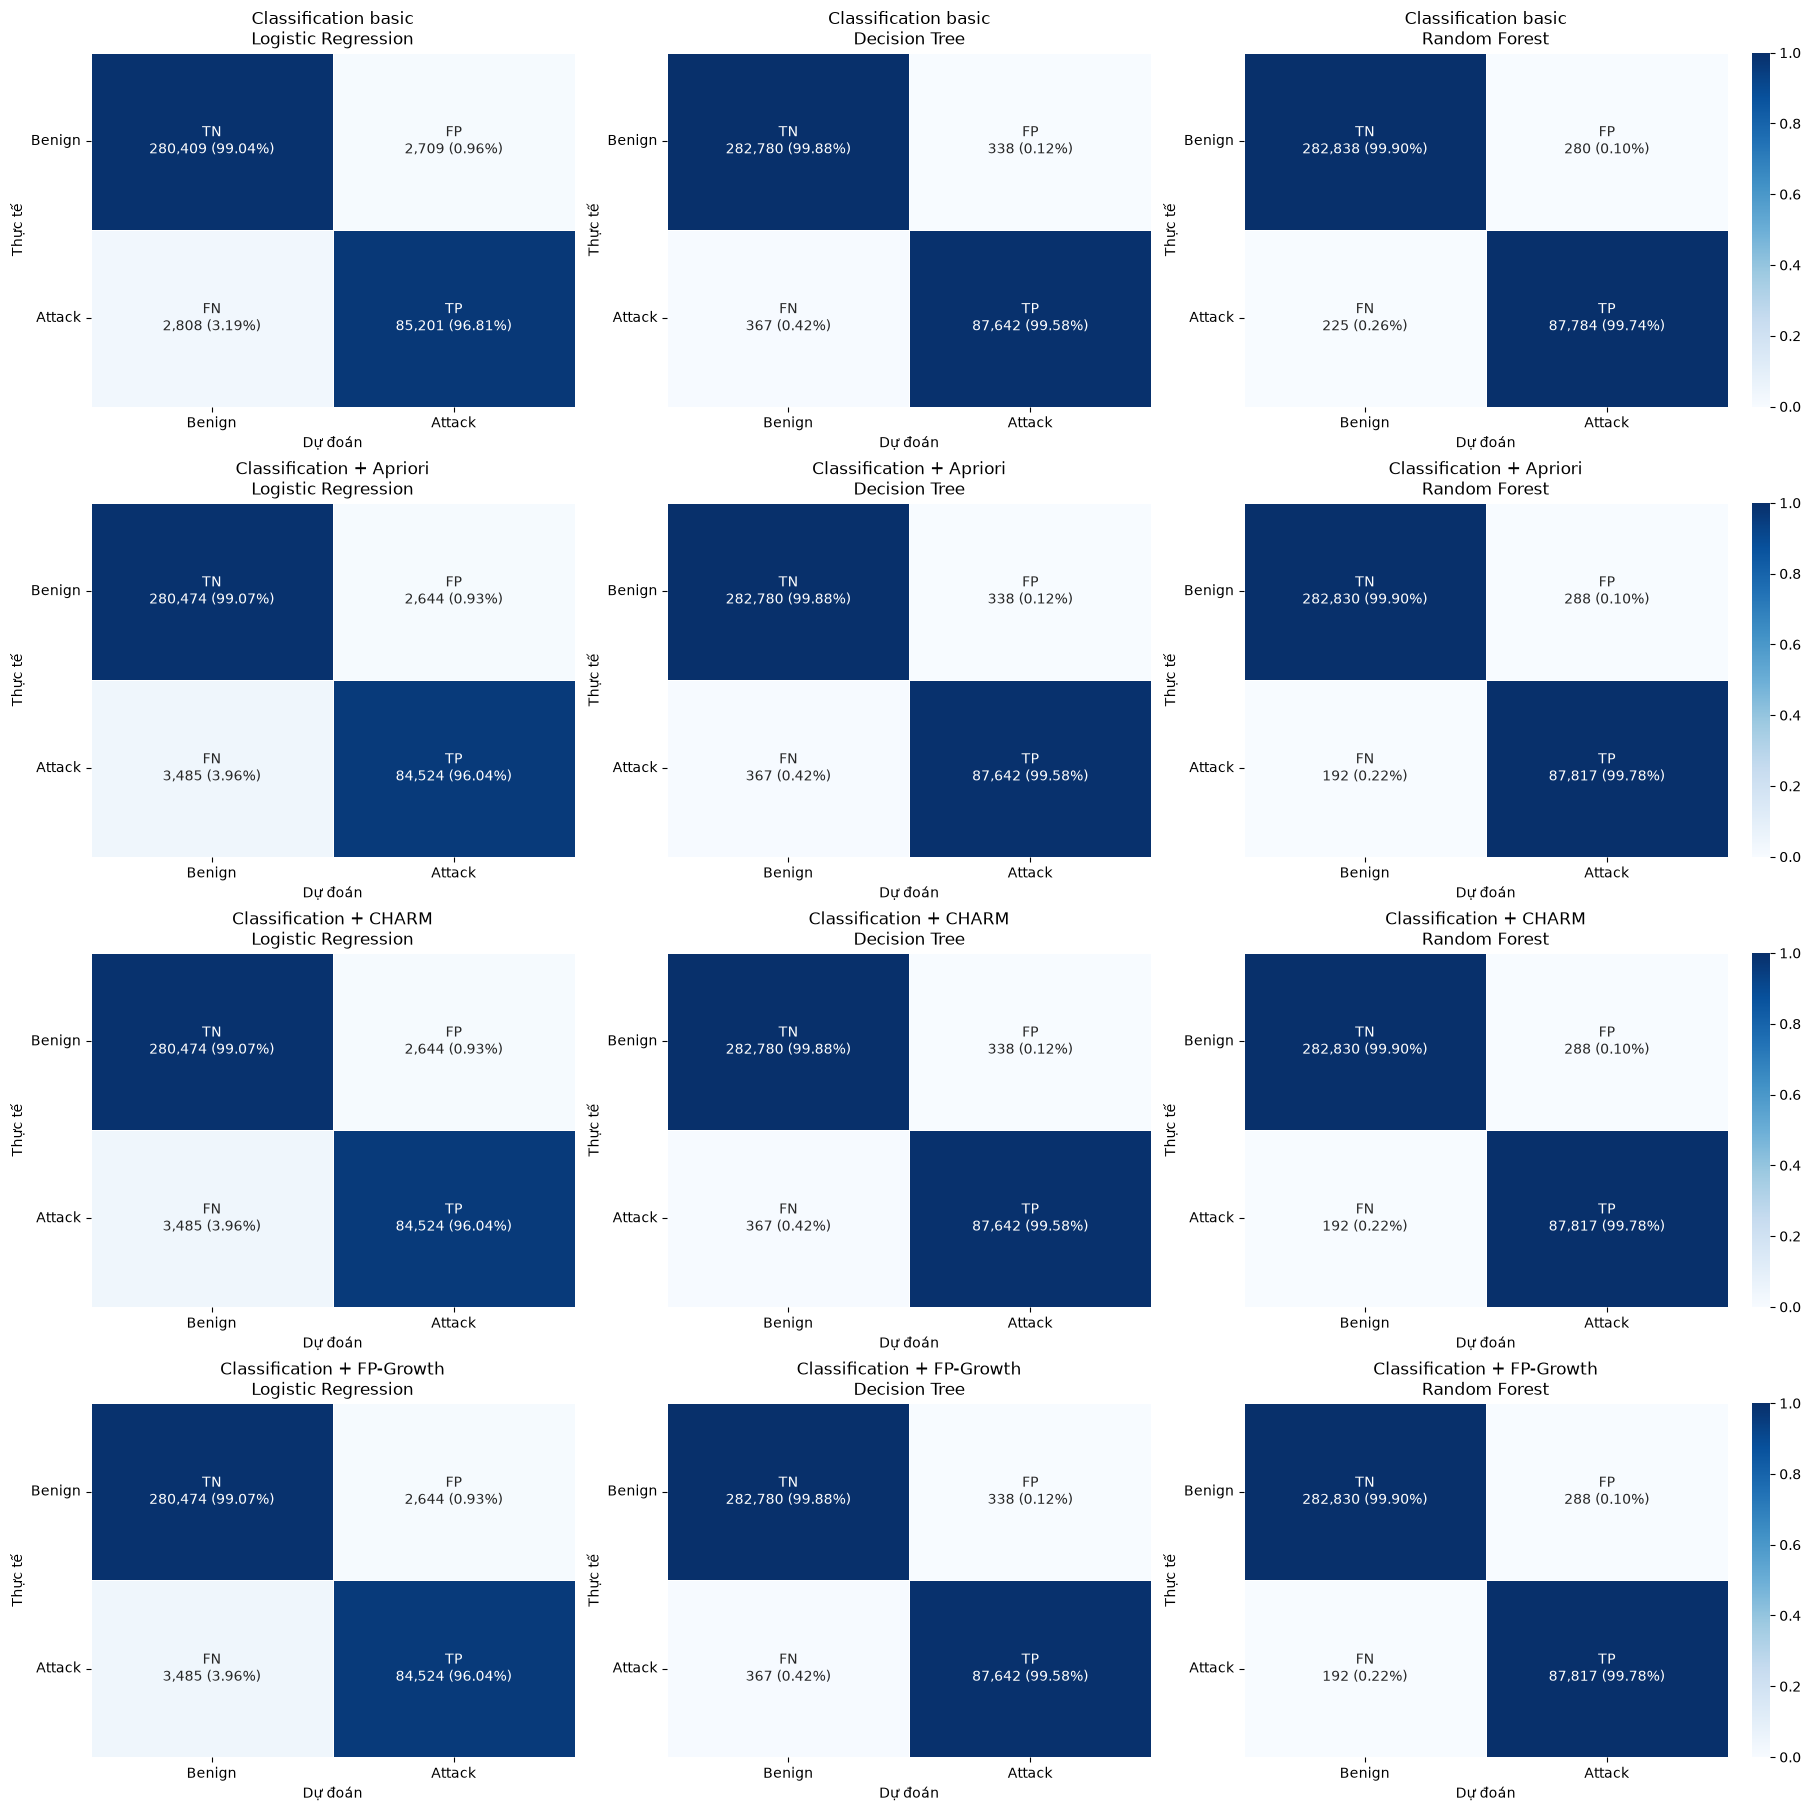

In [51]:
model_order = results["Mô hình"].drop_duplicates().tolist()
fig, axes = plt.subplots(len(datasets), len(model_order), figsize=(18, 4.5 * len(datasets)), constrained_layout=True)

for row, dataset in enumerate(datasets):
    for col, model_name in enumerate(model_order):
        record = confusion_table.loc[
            (confusion_table["Kịch bản phân lớp"] == dataset)
            & (confusion_table["Mô hình"] == model_name)
        ].iloc[0]
        matrix = np.array([
            [record["TN"], record["FP"]],
            [record["FN"], record["TP"]],
        ], dtype=int)
        ratio = matrix / matrix.sum(axis=1, keepdims=True)
        names = [["TN", "FP"], ["FN", "TP"]]
        labels = np.array([
            [f"{names[i][j]}\n{matrix[i, j]:,} ({ratio[i, j]:.2%})" for j in range(2)]
            for i in range(2)
        ])

        sns.heatmap(
            ratio, ax=axes[row, col], annot=labels, fmt="",
            cmap="Blues", vmin=0, vmax=1, linewidths=.5,
            linecolor="white", cbar=(col == 2),
            annot_kws={"fontsize": 10},
            xticklabels=["Benign", "Attack"],
            yticklabels=["Benign", "Attack"],
        )
        axes[row, col].set_title(f"{dataset}\n{model_name}")
        axes[row, col].set_xlabel("Dự đoán")
        axes[row, col].set_ylabel("Thực tế")
        axes[row, col].tick_params(axis="y", rotation=0)

plt.savefig("04_output/03_association_classification/confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## So sánh Precision, Recall, F1 và Accuracy

In [52]:
metric_cols = ["Accuracy", "Precision (attack)", "Recall (attack)", "F1 (attack)"]
scenario_order = {dataset: i for i, dataset in enumerate(datasets)}
score_table = (
    results.assign(_scenario_order=results["Kịch bản phân lớp"].map(scenario_order))
    .sort_values(["Mô hình", "_scenario_order"])
    .drop(columns="_scenario_order")
    .copy()
)


display(
    score_table.style.highlight_max(
        axis=0,
        color="yellow",
        subset=score_table.select_dtypes(include="number").columns
    )
)

,Kịch bản phân lớp,Mô hình,Accuracy,Precision (attack),Recall (attack),F1 (attack)
1,Classification basic,Decision Tree,0.998100,0.996158,0.995830,0.995994
4,Classification + Apriori,Decision Tree,0.998100,0.996158,0.995830,0.995994
7,Classification + CHARM,Decision Tree,0.998100,0.996158,0.995830,0.995994
10,Classification + FP-Growth,Decision Tree,0.998100,0.996158,0.995830,0.995994
0,Classification basic,Logistic Regression,0.985134,0.969184,0.968094,0.968639
3,Classification + Apriori,Logistic Regression,0.983485,0.969668,0.960402,0.965013
6,Classification + CHARM,Logistic Regression,0.983485,0.969668,0.960402,0.965013
9,Classification + FP-Growth,Logistic Regression,0.983485,0.969668,0.960402,0.965013
2,Classification basic,Random Forest,0.998639,0.996820,0.997443,0.997132
5,Classification + Apriori,Random Forest,0.998707,0.996731,0.997818,0.997274


## Mức thay đổi khi thêm luật Apriori, CHARM và FP-Growth

`Δ = chỉ số của kịch bản có luật − chỉ số Classification basic`, đơn vị **điểm phần trăm**. Cả bốn kịch bản giữ cùng feature gốc và cùng tập train/test; mỗi phương pháp khai phá luật bổ sung ba cột `Rule_1`–`Rule_3` riêng. Dấu `+` là tăng, dấu `−` là giảm. Bảng giữ ba chữ số thập phân để không hiện `-0.0`.


In [53]:
model_order = results["Mô hình"].drop_duplicates().tolist()
metric_cols = ["Accuracy", "Precision (attack)", "Recall (attack)", "F1 (attack)"]
d0 = results[results["Kịch bản phân lớp"] == baseline_label].set_index("Mô hình")
effect_rows = []
for dataset in list(datasets)[1:]:
    compared = results[results["Kịch bản phân lớp"] == dataset].set_index("Mô hình")
    for model_name in model_order:
        row = {"Kịch bản phân lớp": dataset, "Mô hình": model_name}
        for metric in metric_cols:
            row[f"Δ {metric} (điểm %)"] = 100 * (
                compared.loc[model_name, metric] - d0.loc[model_name, metric]
            )
        effect_rows.append(row)
effect = pd.DataFrame(effect_rows)

effect_display = effect.copy()
for col in effect.columns[2:]:
    effect_display[col] = effect_display[col].map(
        lambda value: "0.000" if abs(value) < .0005 else f"{value:+.3f}"
    )
display(effect_display)
effect.to_csv("04_output/03_association_classification/rule_feature_effect.csv", index=False)

,Kịch bản phân lớp,Mô hình,Δ Accuracy (điểm %),Δ Precision (attack) (điểm %),Δ Recall (attack) (điểm %),Δ F1 (attack) (điểm %)
0,Classification + Apriori,Logistic Regression,-0.165,+0.048,-0.769,-0.363
1,Classification + Apriori,Decision Tree,0.000,0.000,0.000,0.000
2,Classification + Apriori,Random Forest,+0.007,-0.009,+0.037,+0.014
3,Classification + CHARM,Logistic Regression,-0.165,+0.048,-0.769,-0.363
4,Classification + CHARM,Decision Tree,0.000,0.000,0.000,0.000
5,Classification + CHARM,Random Forest,+0.007,-0.009,+0.037,+0.014
6,Classification + FP-Growth,Logistic Regression,-0.165,+0.048,-0.769,-0.363
7,Classification + FP-Growth,Decision Tree,0.000,0.000,0.000,0.000
8,Classification + FP-Growth,Random Forest,+0.007,-0.009,+0.037,+0.014


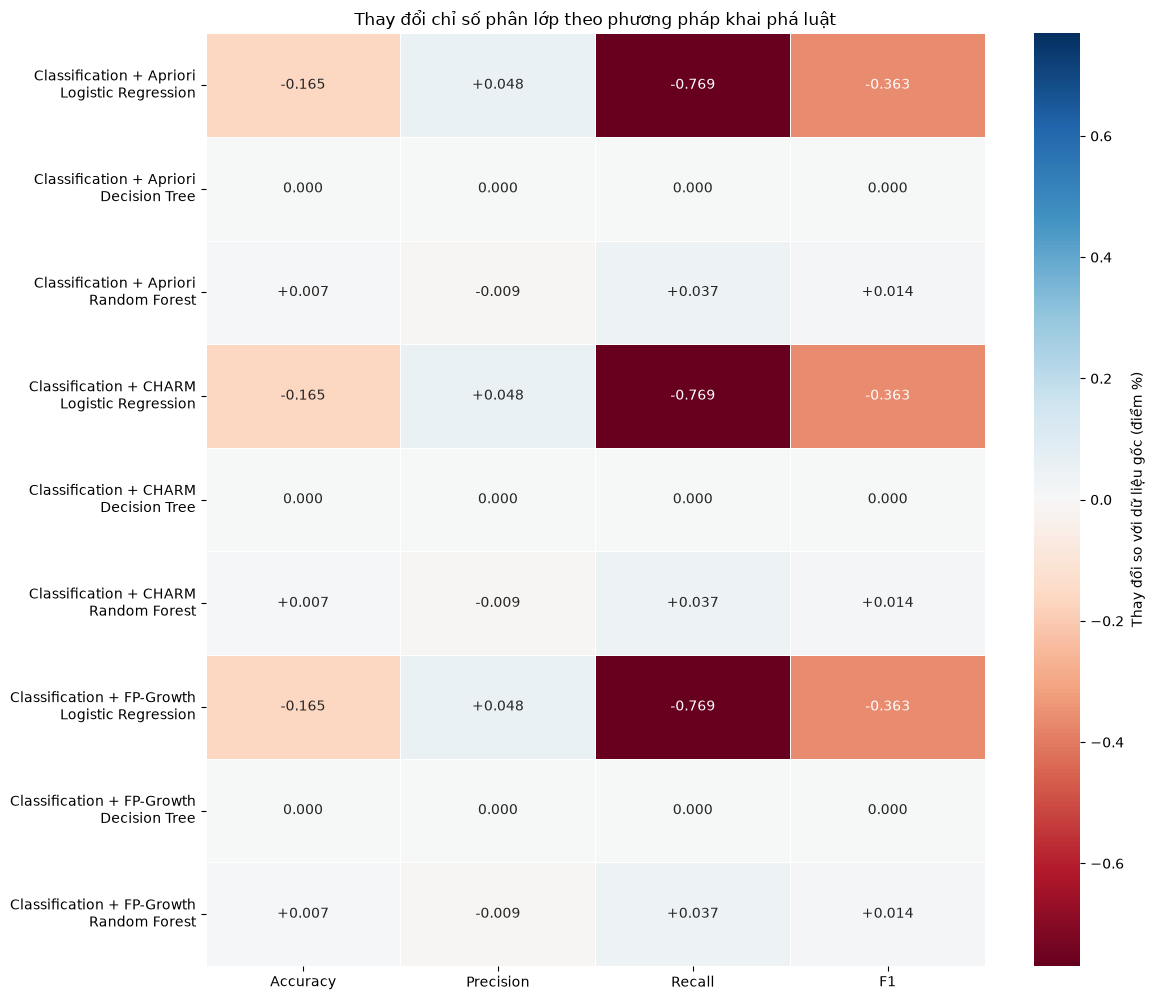

In [54]:
delta = effect.set_index(["Kịch bản phân lớp", "Mô hình"])
delta.columns = ["Accuracy", "Precision", "Recall", "F1"]
delta.index = [f"{scenario}\n{model}" for scenario, model in delta.index]
values = delta.to_numpy()
limit = np.abs(values).max()
annotations = np.array([
    ["0.000" if abs(value) < .0005 else f"{value:+.3f}" for value in row]
    for row in values
])

fig, ax = plt.subplots(figsize=(12, 2 + 0.9 * len(delta)))
sns.heatmap(
    delta, annot=annotations, fmt="", cmap="RdBu", center=0,
    vmin=-limit, vmax=limit, linewidths=.5, linecolor="white",
    cbar_kws={"label": "Thay đổi so với dữ liệu gốc (điểm %)"}, ax=ax,
)
ax.set_title("Thay đổi chỉ số phân lớp theo phương pháp khai phá luật")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("04_output/03_association_classification/metric_changes.png", dpi=160, bbox_inches="tight")
plt.show()